<a href="https://colab.research.google.com/github/Ashwinia04/triallens-clinical-trial-analytics/blob/main/Copy_of_TrialLens_Clinical_Trial_Analytics_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Context & Methods

### Study scenario

TrialLens uses a fictional two-group Phase II study with scheduled Baseline, Week 4, Week 8 and Week 12 visits. The synthetic exports are stored as CSV files in `data/raw/`.

### Analysis approach

1. Load the source CSV exports without silently editing the raw files.
2. Profile row counts, columns, missing values and key identifiers.
3. Run 11 explicit rule-based data-quality checks.
4. Calculate visit completion/window metrics, query closure measures and descriptive adverse-event summaries.
5. Compare paired Baseline-to-Week-12 hsCRP values by randomised group as an exploratory exercise.
6. Query the generated SQLite database using SQL.

### Key assumptions and limitations

- The intended participant grain is one row per `participant_id`; visit grain is participant plus visit; lab grain is participant plus visit plus test.
- The analysis code applies documented eligibility, chronology, deduplication and unit-handling rules. A finding is flagged; it is not automatically corrected in the source export.
- The hsCRP comparison includes only participants with valid Baseline and Week 12 measurements recorded in `mg/L`.
- The AE summaries are descriptive and are not exposure-adjusted or medically adjudicated.
- The simplified query turnaround measure uses records marked Closed with a valid close date.
- The example does not claim CDISC/SDTM conformance, validated EDC integration, GxP validation or production clinical-data-management experience.

In [ ]:
from pathlib import Path
import os
import sys

if "google.colab" in sys.modules:
    from google.colab import files
    import zipfile
    import shutil

    print("Upload: triallens-clinical-trial-analytics-jupyter.zip")
    uploaded_files = files.upload()
    zip_candidates = [name for name in uploaded_files if name.lower().endswith(".zip")]
    if not zip_candidates:
        raise FileNotFoundError("No ZIP file was uploaded. Please upload the TrialLens project ZIP.")

    project_archive = Path("/content") / zip_candidates[0]
    with zipfile.ZipFile(project_archive, "r") as archive:
        archive.extractall("/content")

    project_root = Path("/content/triallens-clinical-trial-analytics")
    if not (project_root / "src" / "triallens").is_dir():
        raise FileNotFoundError("The ZIP did not contain the expected TrialLens project folder.")
    os.chdir(project_root)
    print(f"Project ready: {Path.cwd()}")
else:
    print("Local Jupyter detected. Open this notebook from the extracted TrialLens project folder.")
    print(f"Current folder: {Path.cwd()}")


Upload: triallens-clinical-trial-analytics-jupyter.zip


Saving triallens-clinical-trial-analytics.zip to triallens-clinical-trial-analytics.zip
Project ready: /content/triallens-clinical-trial-analytics


### 0.1 Install the project dependencies

Run this once per fresh Colab runtime. It installs the packages listed in the project's `requirements.txt`.

In [ ]:
%pip install -q -r requirements.txt
print("Dependencies installed.")

Dependencies installed.


### 1. Find the project folder and import libraries

The code searches the current folder and its parent folders for the TrialLens project. This avoids hard-coding a personal Windows or Mac file path.

In [ ]:
from pathlib import Path
import sys
import sqlite3
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Find the project root by looking for the expected folder structure.
search_locations = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next(
    (
        folder for folder in search_locations
        if (folder / "src" / "triallens").is_dir()
        and (folder / "data" / "raw").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "TrialLens project folder was not found. Open Jupyter from the extracted "
        "triallens-clinical-trial-analytics folder, then reopen this notebook."
    )

# Make the project's source code importable in this notebook.
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from triallens.pipeline import load_raw_data, run_pipeline
from triallens.quality import run_quality_checks
from triallens.analysis import analyze_trial

DATA_DIR = PROJECT_ROOT / "data" / "raw"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

print(f"Project folder detected: {PROJECT_ROOT.name}")
print("Raw data folder: data/raw")

Project folder detected: triallens-clinical-trial-analytics
Raw data folder: data/raw


## Data

### 2. Load the six synthetic source exports

Each CSV represents a different data domain. `pandas.read_csv()` loads each file into a DataFrame, which is a tabular data structure used for analysis.

In [ ]:
data = load_raw_data(DATA_DIR)

for dataset_name, frame in data.items():
    print(f"{dataset_name}: {frame.shape[0]:,} rows × {frame.shape[1]:,} columns")

participants: 121 rows × 10 columns
visits: 481 rows × 7 columns
labs: 481 rows × 9 columns
adverse_events: 82 rows × 9 columns
protocol_deviations: 30 rows × 6 columns
queries: 65 rows × 7 columns


### 3. Inspect the participant export

Start by checking the columns and a few rows. This is a basic but important first step before analysing any dataset.

In [ ]:
display(data["participants"].head(8))
print("Participant columns:")
print(data["participants"].columns.tolist())

,participant_id,site_id,country,treatment_arm,age,sex,consent_date,randomization_date,disposition,discontinuation_reason
0,P0001,SITE-01,India,Placebo,64,Male,2025-03-08,2025-03-12,Completed,
1,P0002,SITE-02,United Kingdom,TRX-101,17,Female,2025-04-10,2025-04-11,Completed,
2,P0003,SITE-01,United Kingdom,TRX-101,82,Male,2025-02-06,2025-02-09,Completed,
3,P0004,SITE-01,United Kingdom,TRX-101,23,Male,2025-01-14,2025-01-13,Completed,
4,P0005,SITE-04,India,TRX-101,45,Male,2025-01-24,2025-01-26,Completed,
5,P0006,SITE-01,India,TRX-101,38,Female,2025-02-01,2025-02-06,Completed,
6,P0007,SITE-02,India,Placebo,47,Male,2025-03-01,2025-03-07,Completed,
7,P0008,SITE-02,United Kingdom,TRX-101,65,Male,2025-03-10,2025-03-15,Completed,


Participant columns:
['participant_id', 'site_id', 'country', 'treatment_arm', 'age', 'sex', 'consent_date', 'randomization_date', 'disposition', 'discontinuation_reason']


### 4. Profile row counts, missing values and identifier duplicates

This is a quick source-data profile. The duplicate count is calculated using the intended key for each domain; a duplicate is a review finding, not proof of which row is correct.

In [ ]:
key_columns = {
    "participants": ["participant_id"],
    "visits": ["participant_id", "visit_name"],
    "labs": ["participant_id", "visit_name", "test_name"],
    "adverse_events": ["ae_id"],
    "protocol_deviations": ["deviation_id"],
    "queries": ["query_id"],
}

profile_rows = []
for name, frame in data.items():
    keys = key_columns[name]
    # Treat whitespace-only strings and null values as blank for profiling.
    blank_mask = frame.isna() | frame.apply(
        lambda column: column.astype("string").str.strip().eq("")
    )
    blank_mask = blank_mask.fillna(False)
    profile_rows.append({
        "dataset": name,
        "rows": len(frame),
        "columns": len(frame.columns),
        "blank_or_null_cells": int(blank_mask.sum().sum()),
        "duplicate_key_rows": int(frame.duplicated(keys, keep=False).sum()),
    })

profile = pd.DataFrame(profile_rows)
display(profile)

print("Note: some blank fields are expected (for example, an end date for an open query or a visit date for a visit not performed).")

,dataset,rows,columns,blank_or_null_cells,duplicate_key_rows
0,participants,121,10,115,2
1,visits,481,7,44,2
2,labs,481,9,0,2
3,adverse_events,82,9,0,0
4,protocol_deviations,30,6,0,0
5,queries,65,7,18,0


Note: some blank fields are expected (for example, an end date for an open query or a visit date for a visit not performed).


## Results

### 5. Run the data-quality rules

The validation function checks participant identifiers and eligibility fields, visit records and windows, lab keys and units, adverse-event date chronology, and query closure dates. It returns a traceable issue table with a rule ID, severity, domain and record key.

In [ ]:
quality_issues = run_quality_checks(data)

print(f"Total data-quality findings: {len(quality_issues)}")
display(quality_issues.head(15))

Total data-quality findings: 11


,issue_id,severity,domain,record_key,rule_id,description
0,ISSUE-0001,High,DM,P0001,DM-001,Duplicate participant_id found in the particip...
1,ISSUE-0002,High,DM,P0002,DM-003,Age is missing or outside the protocol eligibi...
2,ISSUE-0003,High,DM,P0003,DM-003,Age is missing or outside the protocol eligibi...
3,ISSUE-0004,Critical,DM,P0004,DM-004,Randomization date is missing/invalid or prece...
4,ISSUE-0005,High,SV,P0005|Week 4,SV-001,More than one record exists for the same parti...
5,ISSUE-0006,High,SV,V00023,SV-002,Visit is marked Completed but actual_date is m...
6,ISSUE-0007,Medium,SV,V00028,SV-003,Completed visit falls outside the permitted vi...
7,ISSUE-0008,High,LB,P0008|Week 12|hsCRP,LB-001,Duplicate participant/visit/test laboratory re...
8,ISSUE-0009,High,LB,L00035,LB-002,Unexpected unit for hsCRP: expected mg/L; rece...
9,ISSUE-0010,Critical,AE,AE00001,AE-001,Adverse-event end_date precedes onset_date.


### 6. Summarise data-quality findings by severity and rule

The chart shows how many findings were raised at each severity level. Severity is assigned by the example rule catalogue; it is not a clinical risk assessment.

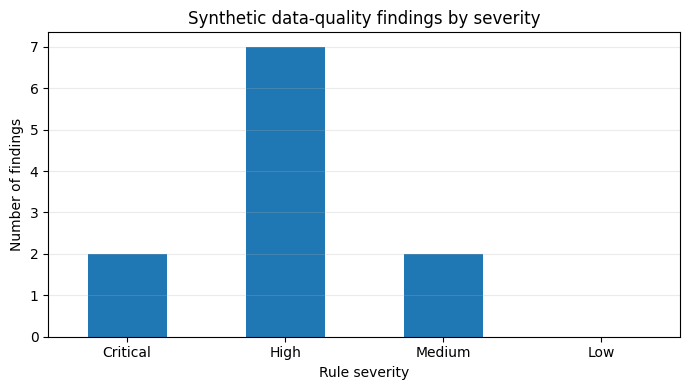

,rule_id,domain,severity,finding_count
0,AE-001,AE,Critical,1
3,DM-004,DM,Critical,1
2,DM-003,DM,High,2
1,DM-001,DM,High,1
4,LB-001,LB,High,1
5,LB-002,LB,High,1
7,SV-001,SV,High,1
8,SV-002,SV,High,1
6,QRY-001,Queries,Medium,1
9,SV-003,SV,Medium,1


In [ ]:
if not quality_issues.empty:
    severity_order = ["Critical", "High", "Medium", "Low"]
    severity_counts = (
        quality_issues["severity"]
        .value_counts()
        .reindex(severity_order, fill_value=0)
    )

    fig, ax = plt.subplots(figsize=(7, 4))
    severity_counts.plot(kind="bar", ax=ax)
    ax.set_title("Synthetic data-quality findings by severity")
    ax.set_xlabel("Rule severity")
    ax.set_ylabel("Number of findings")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

rule_summary = (
    quality_issues.groupby(["rule_id", "domain", "severity"])
    .size()
    .reset_index(name="finding_count")
    .sort_values(["severity", "finding_count"], ascending=[True, False])
)
display(rule_summary)

### 7. Run the study operations and safety analysis

The analysis function applies the documented handling rules and returns summary tables and metrics. We keep the outputs in named variables so each result can be inspected separately.

In [ ]:
analysis = analyze_trial(data)
metrics = analysis["metrics"]

metrics_table = pd.DataFrame(
    [{"metric": name.replace("_", " ").title(), "value": value}
     for name, value in metrics.items()]
)
display(metrics_table)

,metric,value
0,Participants In Raw Export,120
1,Participants In Analysis,117
2,Participant Records In Raw Export,121
3,Adverse Events In Analysis,81
4,Participants With At Least One Ae,59
5,Participants With Ae Pct,50.4
6,Serious Ae Count,6
7,Query Records,65
8,Queries Closed With Valid Close Date,47
9,Query Closure Rate Pct,72.3


### 8. Review visit completion and protocol-window compliance

The within-window rate uses all deduplicated scheduled records in each visit as the denominator. A visit is considered within window only when it is marked Completed, has valid planned and actual dates, and falls within the allowed number of days.

,visit_name,scheduled_records,completed_records,missed_records,within_window_records,completion_rate_pct,within_window_rate_pct
0,Baseline,117,110,7,110,94.0,94.0
1,Week 4,117,107,10,107,91.5,91.5
2,Week 8,117,105,8,104,89.7,88.9
3,Week 12,117,103,8,102,88.0,87.2


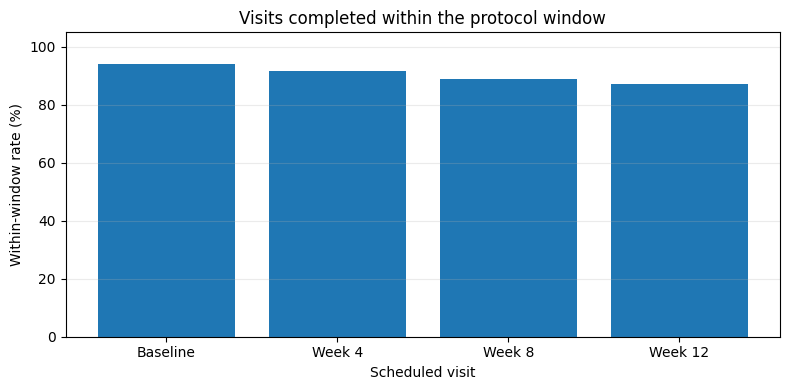

In [ ]:
visit_summary = analysis["visit_summary"]
display(visit_summary)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(visit_summary["visit_name"], visit_summary["within_window_rate_pct"])
ax.set_title("Visits completed within the protocol window")
ax.set_xlabel("Scheduled visit")
ax.set_ylabel("Within-window rate (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 9. Summarise adverse events descriptively

The table groups retained synthetic AE records by randomised group and seriousness. The chart provides a compact comparison of event counts. Counts alone do not account for participant exposure time or establish causality.

,treatment_arm,seriousness,event_count
0,Placebo,Non-serious,30
1,Placebo,Serious,4
2,TRX-101,Non-serious,45
3,TRX-101,Serious,2


Most frequent synthetic AE terms:


,ae_term,event_count
4,Nausea,19
2,Headache,16
5,Upper respiratory tract infection,16
0,Dizziness,13
1,Fatigue,9
3,Injection-site reaction,8


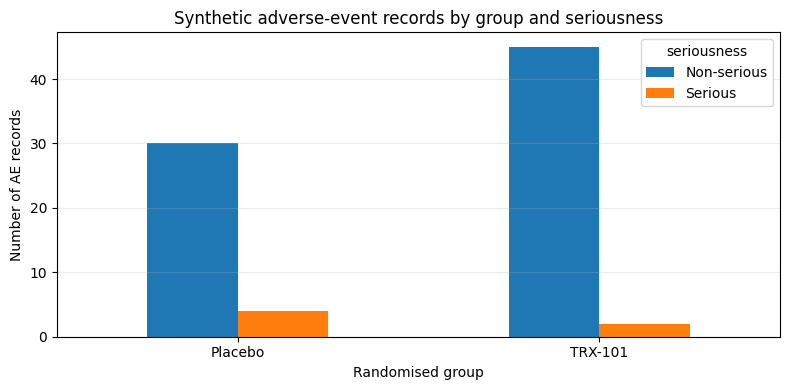

In [ ]:
ae_summary = analysis["ae_summary"]
ae_term_summary = analysis["ae_term_summary"]

display(ae_summary)
print("Most frequent synthetic AE terms:")
display(ae_term_summary.head(10))

if not ae_summary.empty:
    ae_pivot = ae_summary.pivot_table(
        index="treatment_arm", columns="seriousness", values="event_count",
        aggfunc="sum", fill_value=0
    )
    ax = ae_pivot.plot(kind="bar", figsize=(8, 4))
    ax.set_title("Synthetic adverse-event records by group and seriousness")
    ax.set_xlabel("Randomised group")
    ax.set_ylabel("Number of AE records")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

### 10. Review query closure and turnaround

This section illustrates a simple operational query metric. Only queries marked `Closed` with a valid close date are included in the turnaround calculation.

In [ ]:
queries = data["queries"].copy()
queries["opened_date"] = pd.to_datetime(queries["opened_date"], errors="coerce")
queries["closed_date"] = pd.to_datetime(queries["closed_date"], errors="coerce")
valid_closed = queries["status"].eq("Closed") & queries["closed_date"].notna()
queries.loc[valid_closed, "turnaround_days"] = (
    queries.loc[valid_closed, "closed_date"] - queries.loc[valid_closed, "opened_date"]
).dt.days

query_status = queries.groupby("status").size().reset_index(name="query_count")
display(query_status)
print(f"Queries closed with valid close dates: {int(valid_closed.sum())} / {len(queries)}")
print(f"Median turnaround (validly closed queries): {queries.loc[valid_closed, 'turnaround_days'].median():.1f} days")

,status,query_count
0,Closed,48
1,Open,17


Queries closed with valid close dates: 47 / 65
Median turnaround (validly closed queries): 7.0 days


### 11. Explore paired hsCRP measurements

We compare each participant's Week 12 hsCRP result with their Baseline result. Negative change means the recorded Week 12 value is lower than Baseline. Only complete, valid paired observations in `mg/L` are included by the supplied analysis function.

The Welch two-sample t-test and Cohen's d are included as learning examples. Because these are simulated data and this notebook does not perform a complete clinical statistical analysis, do not interpret the p-value as evidence of treatment efficacy.

,treatment_arm,paired_participants,mean_baseline,mean_week12,mean_change,sd_change
0,Placebo,60,8.59,8.05,-0.54,1.29
1,TRX-101,56,8.34,6.34,-1.99,1.21


Participants with valid paired hsCRP records: 116


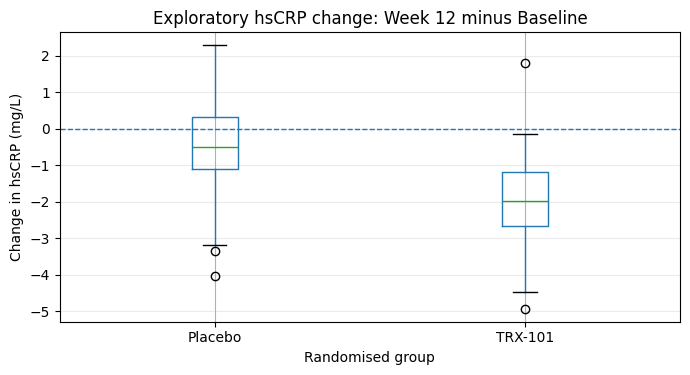

Exploratory Welch test p-value: 6.71e-09
Exploratory Cohen's d: -1.162


In [ ]:
biomarker_summary = analysis["biomarker_summary"]
paired_biomarker_data = analysis["paired_biomarker_data"]

display(biomarker_summary)
print(f"Participants with valid paired hsCRP records: {len(paired_biomarker_data)}")

if not paired_biomarker_data.empty:
    fig, ax = plt.subplots(figsize=(7, 4))
    paired_biomarker_data.boxplot(
        column="change_from_baseline", by="treatment_arm", ax=ax
    )
    fig.suptitle("")
    ax.set_title("Exploratory hsCRP change: Week 12 minus Baseline")
    ax.set_xlabel("Randomised group")
    ax.set_ylabel("Change in hsCRP (mg/L)")
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

print("Exploratory Welch test p-value:", metrics["exploratory_welch_p_value"])
print("Exploratory Cohen's d:", metrics["exploratory_cohens_d"])

### 12. Use SQL to inspect the trial database

The full pipeline creates a SQLite database containing the source tables and the quality-issue table. Here we use SQL directly from the notebook to inspect record counts and data-quality findings.

In [ ]:
# Rebuild all project outputs from the current raw CSV files.
# This also creates outputs/triallens.db and the report/plot files.
pipeline_result = run_pipeline(PROJECT_ROOT, regenerate=False)
DB_PATH = OUTPUT_DIR / "triallens.db"

with sqlite3.connect(DB_PATH) as connection:
    sql_participant_counts = pd.read_sql_query(
        """
        SELECT COUNT(*) AS participant_rows,
               COUNT(DISTINCT participant_id) AS unique_participants
        FROM participants;
        """,
        connection,
    )
    sql_quality_summary = pd.read_sql_query(
        """
        SELECT rule_id, domain, severity, COUNT(*) AS finding_count
        FROM quality_issues
        GROUP BY rule_id, domain, severity
        ORDER BY finding_count DESC, rule_id;
        """,
        connection,
    )

print("Participant export summary:")
display(sql_participant_counts)
print("Quality findings from SQLite:")
display(sql_quality_summary)

Participant export summary:


,participant_rows,unique_participants
0,121,120


Quality findings from SQLite:


,rule_id,domain,severity,finding_count
0,DM-003,DM,High,2
1,AE-001,AE,Critical,1
2,DM-001,DM,High,1
3,DM-004,DM,Critical,1
4,LB-001,LB,High,1
5,LB-002,LB,High,1
6,QRY-001,Queries,Medium,1
7,SV-001,SV,High,1
8,SV-002,SV,High,1
9,SV-003,SV,Medium,1


### 13. Check the generated project outputs

The pipeline saves analysis tables, a SQLite database, visualisations and a Markdown report in the project folder. These files can be reviewed or committed to GitHub.

In [ ]:
expected_outputs = [
    OUTPUT_DIR / "quality_issues.csv",
    OUTPUT_DIR / "visit_summary.csv",
    OUTPUT_DIR / "ae_summary.csv",
    OUTPUT_DIR / "biomarker_summary.csv",
    OUTPUT_DIR / "metrics.json",
    OUTPUT_DIR / "triallens.db",
    OUTPUT_DIR / "plots" / "visit_window_compliance.png",
    PROJECT_ROOT / "reports" / "analysis_summary.md",
]

output_check = pd.DataFrame({
    "file": [str(path.relative_to(PROJECT_ROOT)) for path in expected_outputs],
    "exists": [path.exists() for path in expected_outputs],
})
display(output_check)
assert output_check["exists"].all(), "One or more expected output files are missing."
print("All expected pipeline outputs were created.")

,file,exists
0,outputs/quality_issues.csv,True
1,outputs/visit_summary.csv,True
2,outputs/ae_summary.csv,True
3,outputs/biomarker_summary.csv,True
4,outputs/metrics.json,True
5,outputs/triallens.db,True
6,outputs/plots/visit_window_compliance.png,True
7,reports/analysis_summary.md,True


All expected pipeline outputs were created.
